<p style="height:100px;line-height:100px;background-color:cyan;text-align:center;font-size:52px;font-family:serif;font-weight:bold;color:black;border-radius:12px;">
    Houses Prices - Preparation
</p>

# **1.**
<p style="height:80px;line-height:80px;background-color:lime;padding-left:12px;font-size:36px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:10px;">
    Import Libraries & Data
</p>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from CHE_Functions.GeneralFunctions import getMissingValues, getOutliersLimitis, getObjectsFeaturesList, ObjectToFloat

In [2]:
datasets_path = "Datasets/"

In [3]:
train_data = pd.read_csv(datasets_path + 'train.csv')

In [4]:
test_data = pd.read_csv(datasets_path + 'test.csv')

In [5]:
df_train = train_data.copy()

In [6]:
df_train.shape

(1460, 81)

In [7]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [8]:
df_train.dtypes.value_counts()

object     43
int64      35
float64     3
Name: count, dtype: int64

# **2.**
<p style="height:80px;line-height:80px;background-color:lime;padding-left:12px;font-size:36px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:10px;">
    Data Cleaning
</p>

In [9]:
df_clean = df_train.copy()

## **2.1**
<p style="height:60px;line-height:60px;background-color:navy;padding-left:12px;font-size:32px;font-family:serif;font-weight:bold;color:white;border:1px outset gold;border-radius:8px;">
    Missing Values
</p>

In [10]:
df_null_sum = getMissingValues(df_clean, 0)

<p style="height:60px;line-height:60px;background-color:purple;padding-left:12px;font-size:32px;font-family:serif;font-weight:bold;color:white;border:1px outset gold;border-radius:8px;">
    Dropping Columns
</p>

In [11]:
features_for_drop = df_null_sum[df_null_sum['Percentage'] > 40].index
features_for_drop

Index(['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'MasVnrType', 'FireplaceQu'], dtype='object')

In [12]:
df_clean = df_clean.drop(columns=features_for_drop)

<p style="height:60px;line-height:60px;background-color:purple;padding-left:12px;font-size:32px;font-family:serif;font-weight:bold;color:white;border:1px outset gold;border-radius:8px;">
    Filling NaN Values with `fillna` & Remove Outliers
</p>

In [13]:
features_for_fill = df_null_sum[df_null_sum['Percentage'] <= 40].index
features_for_fill

Index(['LotFrontage', 'GarageYrBlt', 'GarageCond', 'GarageType',
       'GarageFinish', 'GarageQual', 'BsmtFinType2', 'BsmtExposure',
       'BsmtQual', 'BsmtCond', 'BsmtFinType1', 'MasVnrArea', 'Electrical'],
      dtype='object')

In [14]:
df_clean[features_for_fill].dtypes

LotFrontage     float64
GarageYrBlt     float64
GarageCond       object
GarageType       object
GarageFinish     object
GarageQual       object
BsmtFinType2     object
BsmtExposure     object
BsmtQual         object
BsmtCond         object
BsmtFinType1     object
MasVnrArea      float64
Electrical       object
dtype: object

In [15]:
# Continuous Nymerical Variables
cont_numr_vars = [
                    'LotFrontage',
                    'LotArea',
                    'MasVnrArea',
                    'BsmtFinSF1',
                    'BsmtFinSF2',
                    'TotalBsmtSF',
                    '1stFlrSF',
                    '2ndFlrSF',
                    'LowQualFinSF',
                    'GrLivArea',
                    'GarageArea',
                    'WoodDeckSF',
                    'OpenPorchSF',
                    'EnclosedPorch',
                    '3SsnPorch',
                    'ScreenPorch',
                    'PoolArea',
                    'MiscVal'
                ]

### **2.1.1**
<p style="height:50px;line-height:50px;background-color:yellow;padding-left:12px;font-size:28px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:6px;">
    LotFrontage Feature
</p>

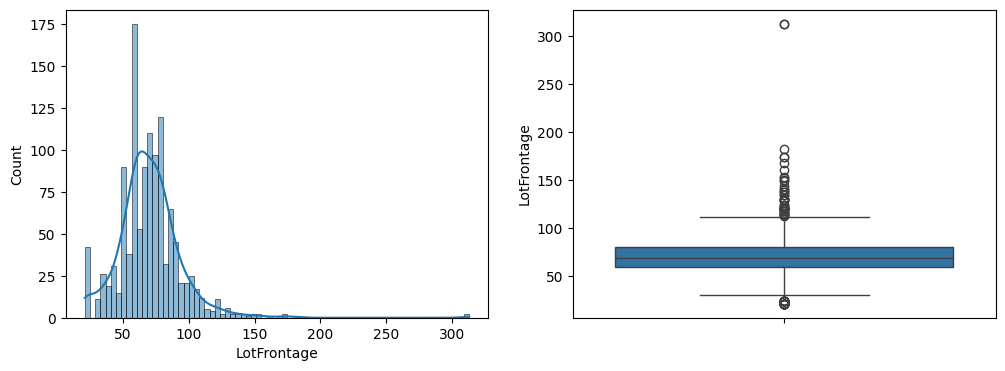

In [16]:
plt.figure(figsize=(12, 4))

plt.subplot2grid((1, 2), (0, 0))
sns.histplot(df_clean['LotFrontage'], kde=True)

plt.subplot2grid((1, 2), (0, 1))
sns.boxplot(df_clean['LotFrontage'])

plt.show()

In [17]:
masvnr_mean = np.ceil(df_clean['LotFrontage'].mean())

In [18]:
df_clean['LotFrontage'] = df_clean['LotFrontage'].fillna(masvnr_mean)

In [19]:
features_for_fill = features_for_fill.drop('LotFrontage')

### **2.1.2**
<p style="height:50px;line-height:50px;background-color:yellow;padding-left:12px;font-size:28px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:6px;">
    LotArea Feature
</p>

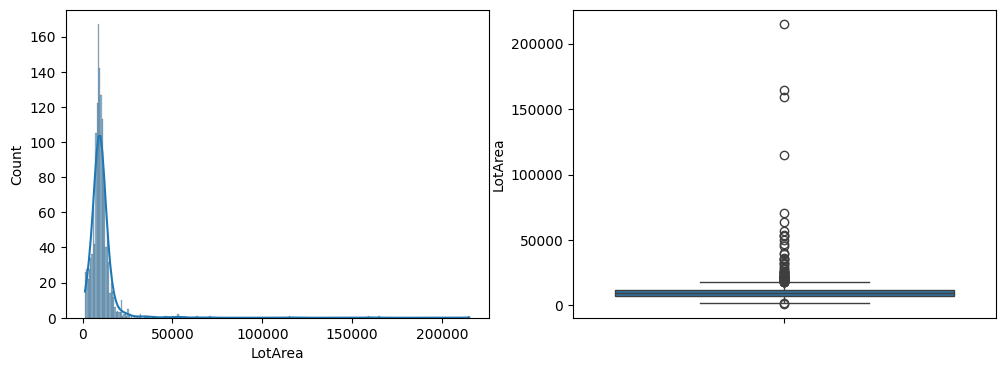

In [20]:
plt.figure(figsize=(12, 4))

plt.subplot2grid((1, 2), (0, 0))
sns.histplot(df_clean['LotArea'], kde=True)

plt.subplot2grid((1, 2), (0, 1))
sns.boxplot(df_clean['LotArea'])

plt.show()

### **2.1.3**
<p style="height:50px;line-height:50px;background-color:yellow;padding-left:12px;font-size:28px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:6px;">
    MasVnrArea Feature
</p>

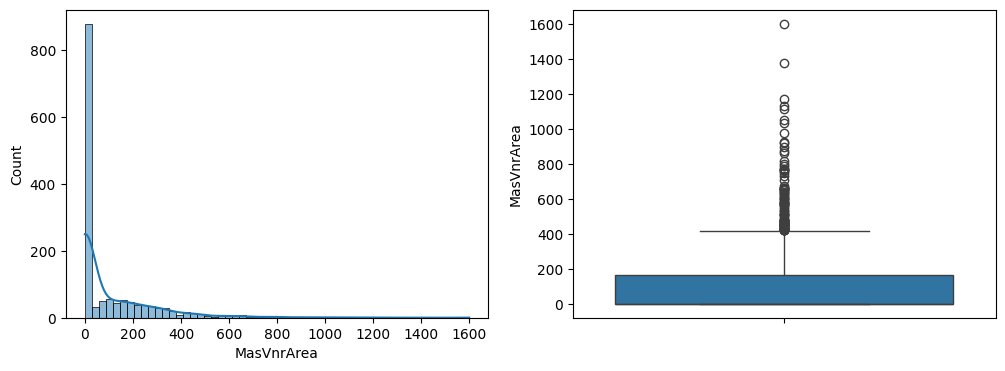

In [21]:
plt.figure(figsize=(12, 4))

plt.subplot2grid((1, 2), (0, 0))
sns.histplot(df_clean['MasVnrArea'], kde=True)

plt.subplot2grid((1, 2), (0, 1))
sns.boxplot(df_clean['MasVnrArea'])

plt.show()

In [22]:
masvnr_mean = np.ceil(df_clean['MasVnrArea'].mean())

In [23]:
df_clean['MasVnrArea'] = df_clean['MasVnrArea'].fillna(masvnr_mean)

In [24]:
features_for_fill = features_for_fill.drop('MasVnrArea')

### **2.1.4**
<p style="height:50px;line-height:50px;background-color:yellow;padding-left:12px;font-size:28px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:6px;">
    BsmtFinSF1 Feature
</p>

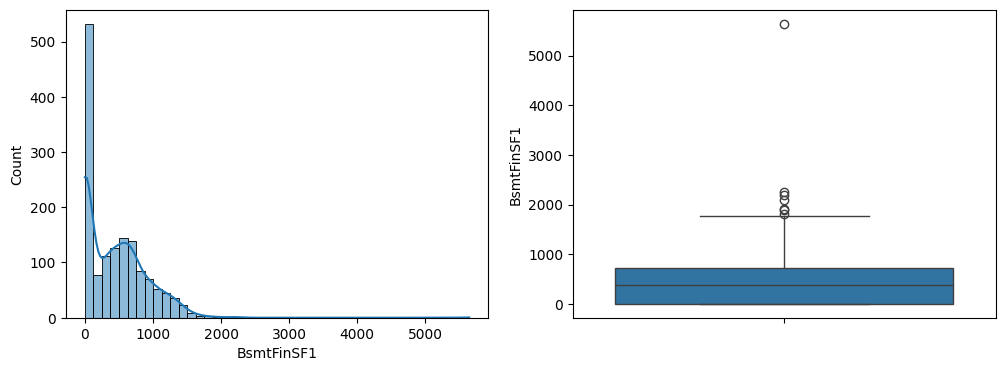

In [25]:
plt.figure(figsize=(12, 4))

plt.subplot2grid((1, 2), (0, 0))
sns.histplot(df_clean['BsmtFinSF1'], kde=True)

plt.subplot2grid((1, 2), (0, 1))
sns.boxplot(df_clean['BsmtFinSF1'])

plt.show()

### **2.1.5**
<p style="height:50px;line-height:50px;background-color:yellow;padding-left:12px;font-size:28px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:6px;">
    BsmtFinSF2 Feature
</p>

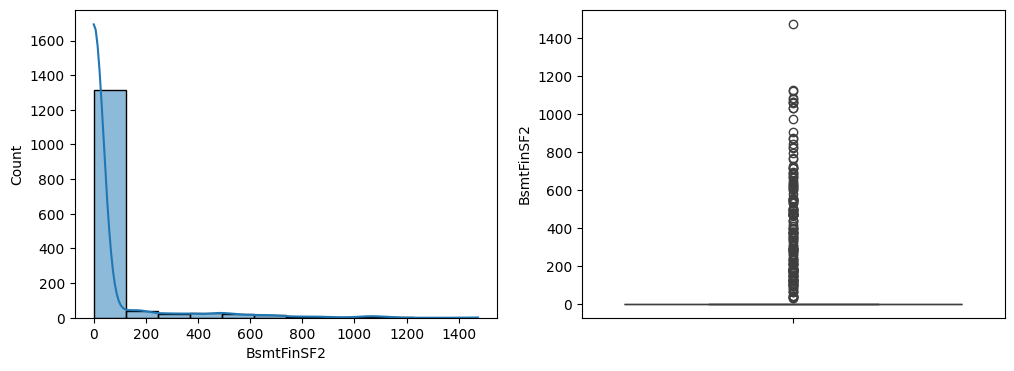

In [26]:
plt.figure(figsize=(12, 4))

plt.subplot2grid((1, 2), (0, 0))
sns.histplot(df_clean['BsmtFinSF2'], kde=True)

plt.subplot2grid((1, 2), (0, 1))
sns.boxplot(df_clean['BsmtFinSF2'])

plt.show()

### **2.1.6**
<p style="height:50px;line-height:50px;background-color:yellow;padding-left:12px;font-size:28px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:6px;">
    TotalBsmtSF Feature
</p>

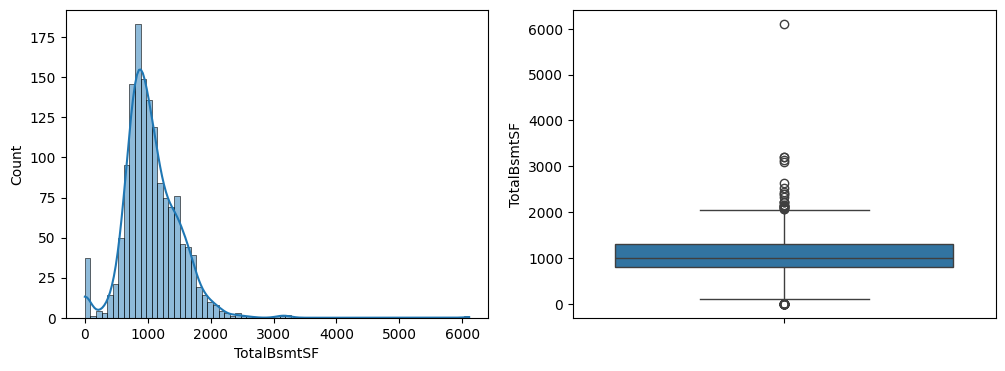

In [27]:
plt.figure(figsize=(12, 4))

plt.subplot2grid((1, 2), (0, 0))
sns.histplot(df_clean['TotalBsmtSF'], kde=True)

plt.subplot2grid((1, 2), (0, 1))
sns.boxplot(df_clean['TotalBsmtSF'])

plt.show()

### **2.1.7**
<p style="height:50px;line-height:50px;background-color:yellow;padding-left:12px;font-size:28px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:6px;">
    1stFlrSF Feature
</p>

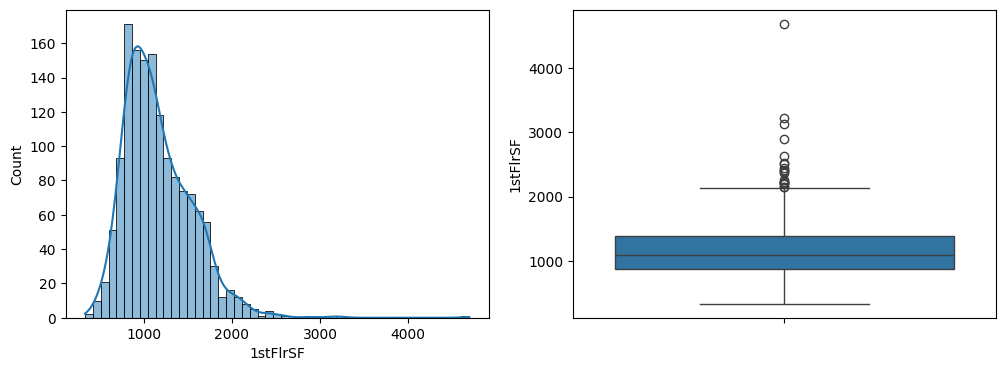

In [28]:
plt.figure(figsize=(12, 4))

plt.subplot2grid((1, 2), (0, 0))
sns.histplot(df_clean['1stFlrSF'], kde=True)

plt.subplot2grid((1, 2), (0, 1))
sns.boxplot(df_clean['1stFlrSF'])

plt.show()

### **2.1.8**
<p style="height:50px;line-height:50px;background-color:yellow;padding-left:12px;font-size:28px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:6px;">
    2ndFlrSF Feature
</p>

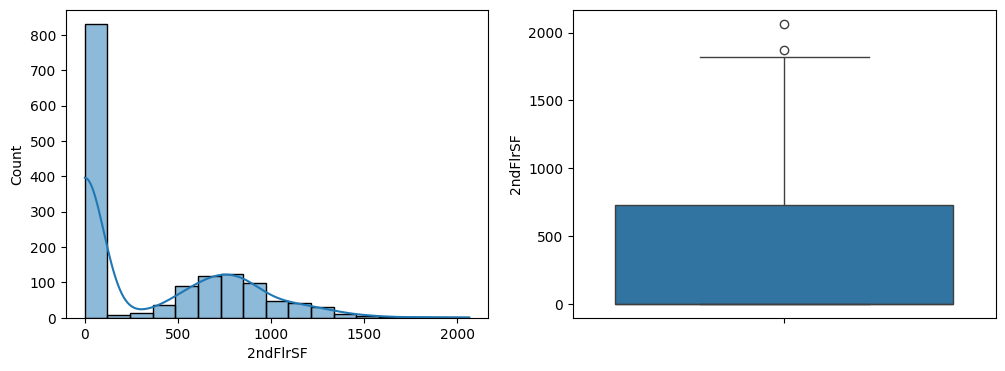

In [29]:
plt.figure(figsize=(12, 4))

plt.subplot2grid((1, 2), (0, 0))
sns.histplot(df_clean['2ndFlrSF'], kde=True)

plt.subplot2grid((1, 2), (0, 1))
sns.boxplot(df_clean['2ndFlrSF'])

plt.show()

### **2.1.9**
<p style="height:50px;line-height:50px;background-color:yellow;padding-left:12px;font-size:28px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:6px;">
    LowQualFinSF Feature
</p>

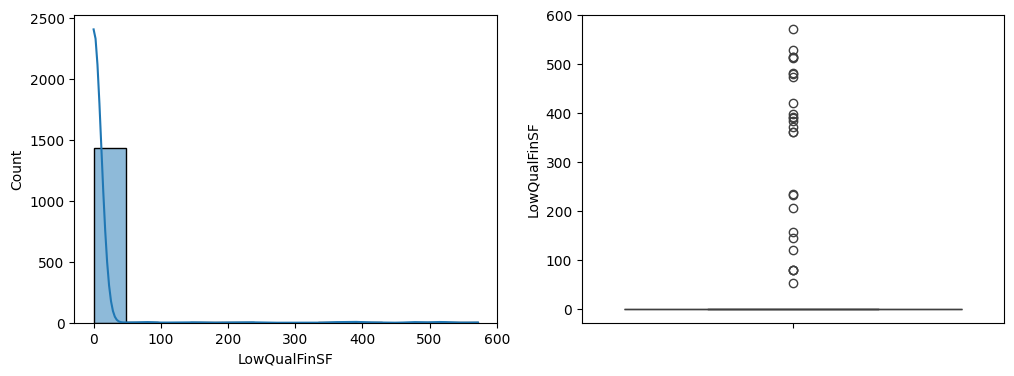

In [30]:
plt.figure(figsize=(12, 4))

plt.subplot2grid((1, 2), (0, 0))
sns.histplot(df_clean['LowQualFinSF'], kde=True)

plt.subplot2grid((1, 2), (0, 1))
sns.boxplot(df_clean['LowQualFinSF'])

plt.show()

### **2.1.10**
<p style="height:50px;line-height:50px;background-color:yellow;padding-left:12px;font-size:28px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:6px;">
    GrLivArea Feature
</p>

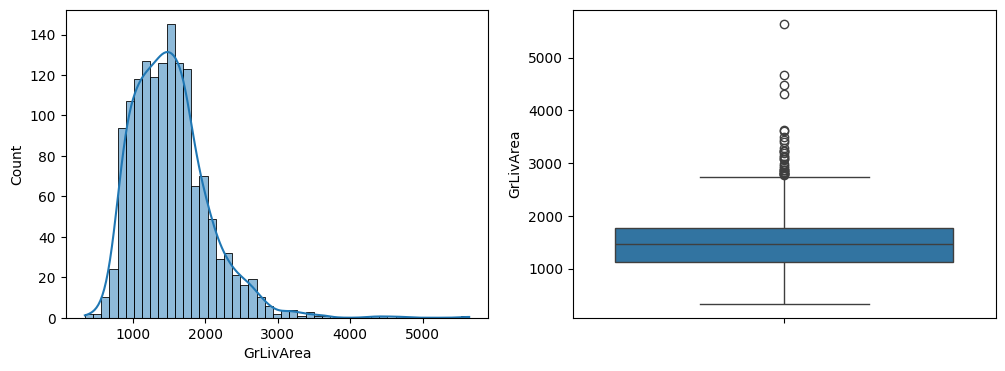

In [31]:
plt.figure(figsize=(12, 4))

plt.subplot2grid((1, 2), (0, 0))
sns.histplot(df_clean['GrLivArea'], kde=True)

plt.subplot2grid((1, 2), (0, 1))
sns.boxplot(df_clean['GrLivArea'])

plt.show()

### **2.1.11**
<p style="height:50px;line-height:50px;background-color:yellow;padding-left:12px;font-size:28px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:6px;">
    GarageArea Feature
</p>

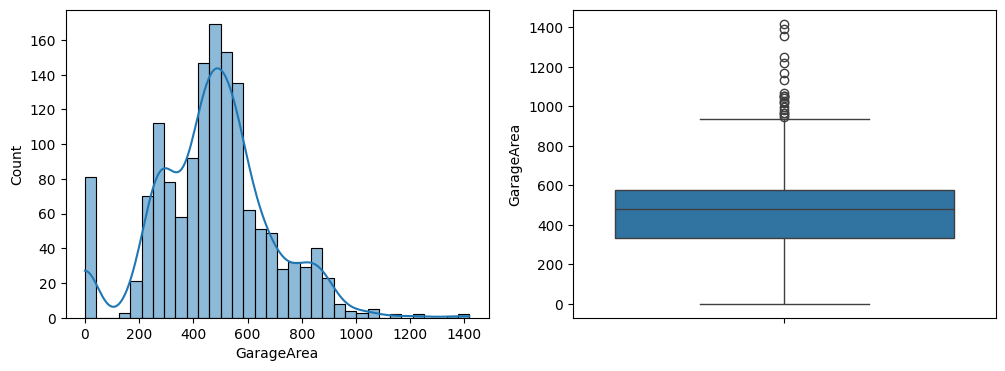

In [32]:
plt.figure(figsize=(12, 4))

plt.subplot2grid((1, 2), (0, 0))
sns.histplot(df_clean['GarageArea'], kde=True)

plt.subplot2grid((1, 2), (0, 1))
sns.boxplot(df_clean['GarageArea'])

plt.show()

### **2.1.12**
<p style="height:50px;line-height:50px;background-color:yellow;padding-left:12px;font-size:28px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:6px;">
    WoodDeckSF Feature
</p>

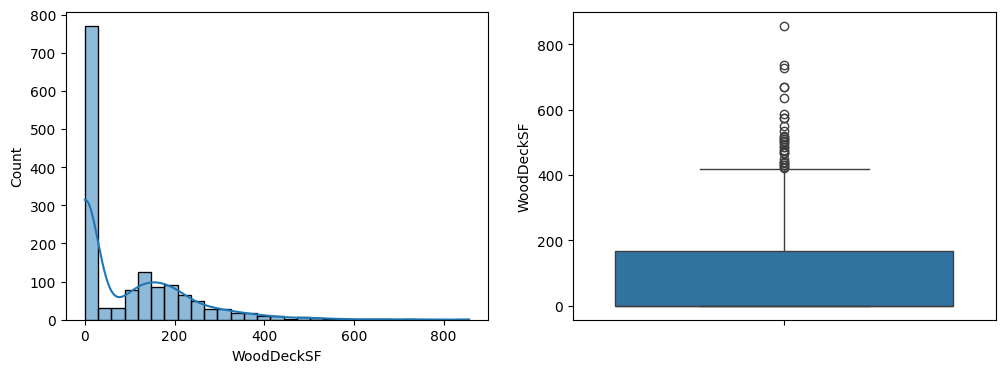

In [33]:
plt.figure(figsize=(12, 4))

plt.subplot2grid((1, 2), (0, 0))
sns.histplot(df_clean['WoodDeckSF'], kde=True)

plt.subplot2grid((1, 2), (0, 1))
sns.boxplot(df_clean['WoodDeckSF'])

plt.show()

### **2.1.13**
<p style="height:50px;line-height:50px;background-color:yellow;padding-left:12px;font-size:28px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:6px;">
    OpenPorchSF Feature
</p>

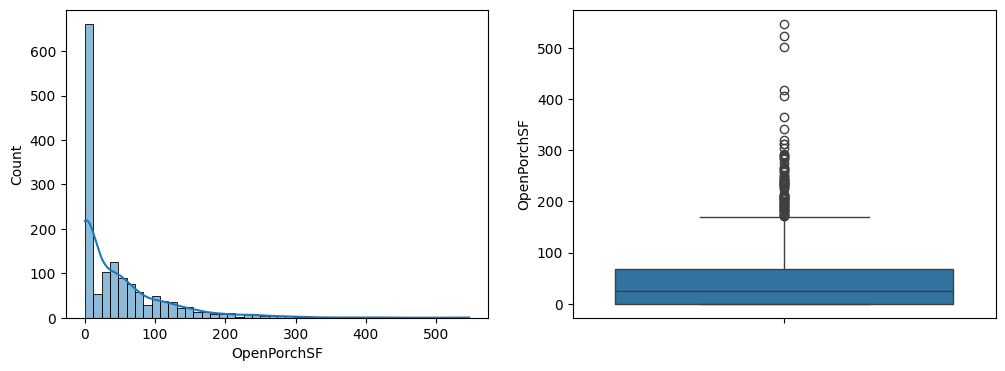

In [34]:
plt.figure(figsize=(12, 4))

plt.subplot2grid((1, 2), (0, 0))
sns.histplot(df_clean['OpenPorchSF'], kde=True)

plt.subplot2grid((1, 2), (0, 1))
sns.boxplot(df_clean['OpenPorchSF'])

plt.show()

### **2.1.14**
<p style="height:50px;line-height:50px;background-color:yellow;padding-left:12px;font-size:28px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:6px;">
    EnclosedPorch Feature
</p>

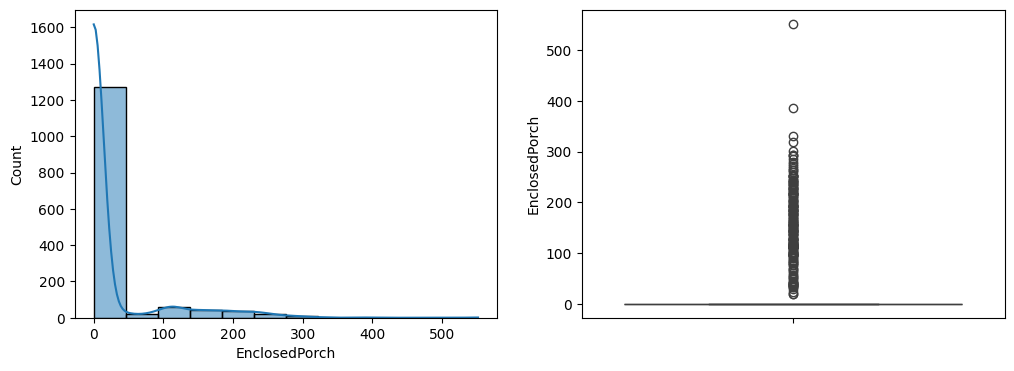

In [35]:
plt.figure(figsize=(12, 4))

plt.subplot2grid((1, 2), (0, 0))
sns.histplot(df_clean['EnclosedPorch'], kde=True)

plt.subplot2grid((1, 2), (0, 1))
sns.boxplot(df_clean['EnclosedPorch'])

plt.show()

### **2.1.15**
<p style="height:50px;line-height:50px;background-color:yellow;padding-left:12px;font-size:28px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:6px;">
    3SsnPorch Feature
</p>

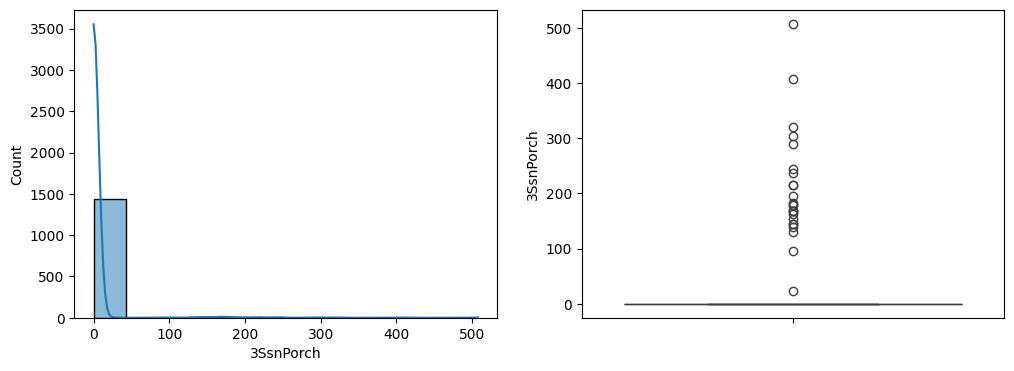

In [36]:
plt.figure(figsize=(12, 4))

plt.subplot2grid((1, 2), (0, 0))
sns.histplot(df_clean['3SsnPorch'], kde=True)

plt.subplot2grid((1, 2), (0, 1))
sns.boxplot(df_clean['3SsnPorch'])

plt.show()

### **2.1.16**
<p style="height:50px;line-height:50px;background-color:yellow;padding-left:12px;font-size:28px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:6px;">
    ScreenPorch Feature
</p>

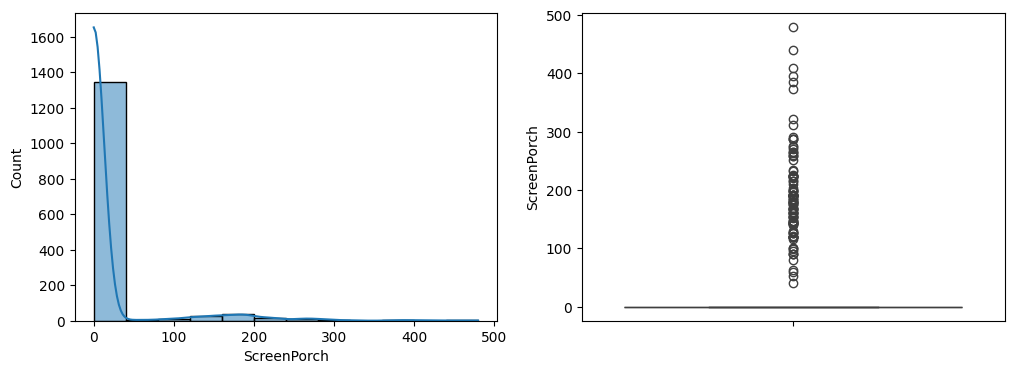

In [37]:
plt.figure(figsize=(12, 4))

plt.subplot2grid((1, 2), (0, 0))
sns.histplot(df_clean['ScreenPorch'], kde=True)

plt.subplot2grid((1, 2), (0, 1))
sns.boxplot(df_clean['ScreenPorch'])

plt.show()

### **2.1.17**
<p style="height:50px;line-height:50px;background-color:yellow;padding-left:12px;font-size:28px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:6px;">
    PoolArea Feature
</p>

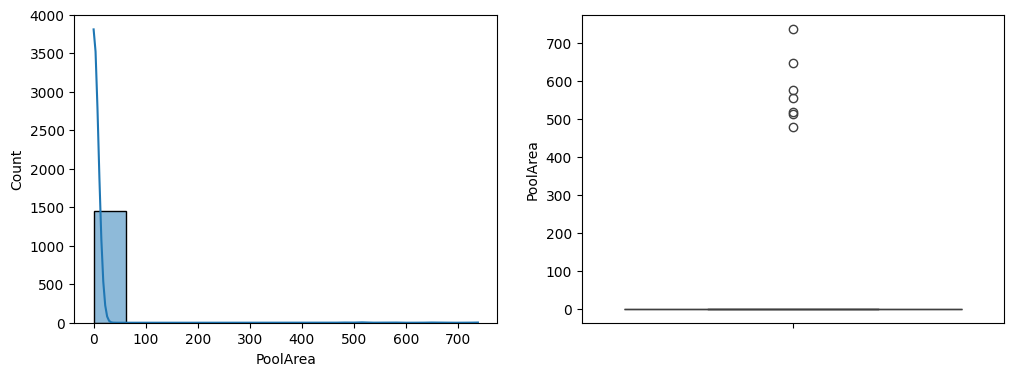

In [38]:
plt.figure(figsize=(12, 4))

plt.subplot2grid((1, 2), (0, 0))
sns.histplot(df_clean['PoolArea'], kde=True)

plt.subplot2grid((1, 2), (0, 1))
sns.boxplot(df_clean['PoolArea'])

plt.show()

### **2.1.18**
<p style="height:50px;line-height:50px;background-color:yellow;padding-left:12px;font-size:28px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:6px;">
    MiscVal Feature
</p>

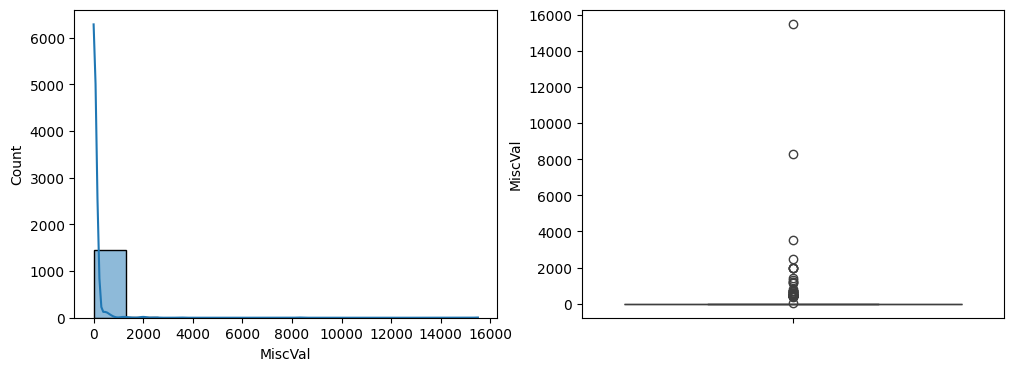

In [39]:
plt.figure(figsize=(12, 4))

plt.subplot2grid((1, 2), (0, 0))
sns.histplot(df_clean['MiscVal'], kde=True)

plt.subplot2grid((1, 2), (0, 1))
sns.boxplot(df_clean['MiscVal'])

plt.show()

### **2.1.19**
<p style="height:50px;line-height:50px;background-color:yellow;padding-left:12px;font-size:28px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:6px;">
    GarageYrBlt Feature
</p>

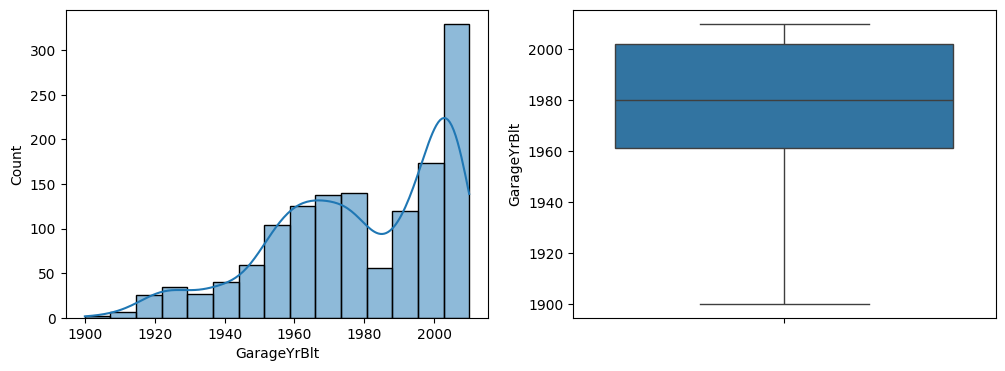

In [40]:
plt.figure(figsize=(12, 4))

plt.subplot2grid((1, 2), (0, 0))
sns.histplot(df_clean['GarageYrBlt'], kde=True)

plt.subplot2grid((1, 2), (0, 1))
sns.boxplot(df_clean['GarageYrBlt'])

plt.show()

In [41]:
garyrblt_mode = df_clean['GarageYrBlt'].mode()

In [42]:
df_clean['GarageYrBlt'] = df_clean['GarageYrBlt'].fillna(garyrblt_mode)

In [43]:
features_for_fill = features_for_fill.drop('GarageYrBlt')

### **2.1.20**
<p style="height:50px;line-height:50px;background-color:yellow;padding-left:12px;font-size:28px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:6px;">
    SalePrice Feature
</p>

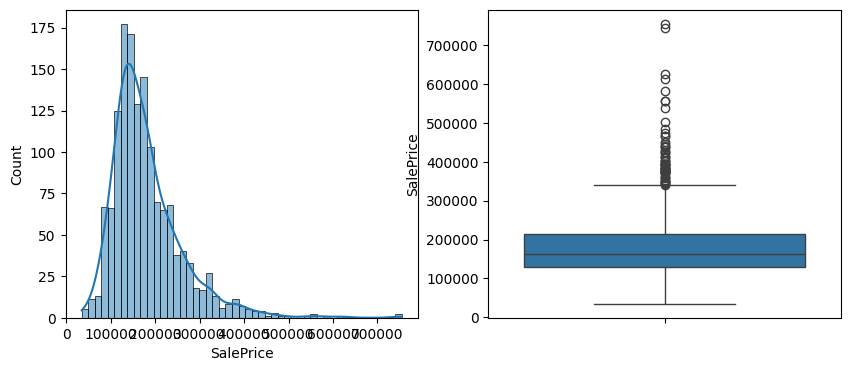

In [44]:
plt.figure(figsize=(10, 4))

plt.subplot2grid((1, 2), (0, 0))
sns.histplot(df_clean['SalePrice'], kde=True)

plt.subplot2grid((1, 2), (0, 1))
sns.boxplot(df_clean['SalePrice'])

plt.show()

### **2.1.4**
<p style="height:50px;line-height:50px;background-color:yellow;padding-left:12px;font-size:28px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:6px;">
    Categorical Features
</p>

In [45]:
fill_dict = {}
for col in features_for_fill:
    print(col)
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode().values[0])

GarageCond
GarageType
GarageFinish
GarageQual
BsmtFinType2
BsmtExposure
BsmtQual
BsmtCond
BsmtFinType1
Electrical


In [46]:
getMissingValues(df_clean)

,Count,Percentage
GarageYrBlt,81,5.547945


_________________________

## **2.2**
<p style="height:60px;line-height:60px;background-color:navy;padding-left:12px;font-size:32px;font-family:serif;font-weight:bold;color:white;border:1px outset gold;border-radius:8px;">
    Convert Data to Numerical
</p>

In [47]:
df_numeric = df_clean.copy()

In [48]:
train_objects_features = getObjectsFeaturesList(df_numeric)

In [49]:
df_numeric = ObjectToFloat(df_numeric, train_objects_features)    # 'CHE_Functions' method

In [50]:
corr_train = df_numeric.corr()

In [51]:
for f in corr_train['SalePrice'].sort_values(ascending=False).index:
    print(f"{f} : {corr_train['SalePrice'][f]}")

SalePrice : 1.0
OverallQual : 0.7909816005838053
GrLivArea : 0.7086244776126515
GarageCars : 0.6404091972583519
GarageArea : 0.6234314389183622
TotalBsmtSF : 0.6135805515591943
1stFlrSF : 0.6058521846919153
ExterQual : 0.5670787484325334
FullBath : 0.5606637627484453
GarageFinish : 0.5372421226773465
TotRmsAbvGrd : 0.5337231555820284
YearBuilt : 0.5228973328794967
YearRemodAdd : 0.5071009671113866
BsmtQual : 0.4954275535504876
GarageYrBlt : 0.4863616774878596
MasVnrArea : 0.47524799741497165
Fireplaces : 0.46692883675152763
KitchenQual : 0.4605168709143811
BsmtFinSF1 : 0.3864198062421535
LotFrontage : 0.33492271716930605
WoodDeckSF : 0.32441344456812926
2ndFlrSF : 0.31933380283206736
OpenPorchSF : 0.31585622711605504
HalfBath : 0.28410767559478256
BsmtExposure : 0.27604293648779266
LotShape : 0.2677593139178233
LotArea : 0.2638433538714051
BsmtFullBath : 0.22712223313149427
BsmtUnfSF : 0.21447910554696928
BedroomAbvGr : 0.16821315430073963
RoofStyle : 0.15627230994535124
Neighborhood :

In [52]:
best_corr_cols = corr_train[corr_train['SalePrice'].abs() > 0.4].index
best_corr_cols

Index(['OverallQual', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'ExterQual',
       'Foundation', 'BsmtQual', 'TotalBsmtSF', '1stFlrSF', 'GrLivArea',
       'FullBath', 'KitchenQual', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt',
       'GarageFinish', 'GarageCars', 'GarageArea', 'SalePrice'],
      dtype='object')

# **2.**
<p style="height:80px;line-height:80px;background-color:lime;padding-left:12px;font-size:36px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:10px;">
    Export Data
</p>

In [53]:
df_clean.to_csv('Datasets/df_clean.csv', index=False)

In [54]:
df_numeric.to_csv('Datasets/df_numeric.csv', index=False)

# **Kaggle : [Tarek Ghajary](www.kaggle.com/tarekghajary) | GitHub : [CHESyrian](www.github.com/CHESyrian) | Linkedin : [Tarek Ghajary](https://www.linkedin.com/in/tarek-ghajary-95ab0b195/)**
<p style="height:240px;line-height:100px;font-size:64px;background-color:cyan;color:white;padding:20px auto;text-align:center;border:2px outset gold;border-radius:8px;">
    Created by:<br/> <code style="border:1px outset gold;border-radius:10px;">Tarek Ghajary</code>
</p>